# Consumer Complaint Classification
Predict the product category of a customer complaint and compare **4 models**: SimpleRNN, LSTM, GRU, and fine-tuned DistilBERT.

**How to run:** set `Accelerator = GPU`, `Internet = On`, add the dataset, then press **Run All**.

| Part | What happens |
|---|---|
| 1-4 | Load data, clean it, split it |
| 5 | Train DistilBERT (in a separate process, ~10-15 min) |
| 6-10 | Tokenize and train SimpleRNN / LSTM / GRU |
| 11-12 | Evaluate DistilBERT and compare all models |

## 1) Imports and Settings
All settings are in one place. Note that TensorFlow is **not** imported yet (it is imported later, after DistilBERT finishes), so the two frameworks never fight over the GPU.

In [1]:
import os, re, glob, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

SEED = 42
SAMPLE_SIZE = 50000     # number of complaints to use (lower = faster)
MIN_PER_CLASS = 500     # drop categories with fewer samples than this
VOCAB_SIZE = 20000      # RNN vocabulary size
MAX_LEN = 200           # RNN sequence length
EMB_DIM = 100           # RNN embedding size
BATCH_SIZE = 128
EPOCHS = 15

random.seed(SEED); np.random.seed(SEED)

## 2) Load the Data
The file has two useful columns: `narrative` (the complaint text) and `product` (the category we want to predict).

In [2]:
DATA_PATH = glob.glob("/kaggle/input/**/complaints_processed.csv", recursive=True)[0]
df = pd.read_csv(DATA_PATH)[["narrative", "product"]].dropna()
df = df.rename(columns={"narrative": "raw", "product": "label"})
print("Shape:", df.shape)
df.head()

Shape: (162411, 2)


,raw,label
0,purchase order day shipping amount receive pro...,credit_card
1,forwarded message date tue subject please inve...,credit_card
2,forwarded message cc sent friday pdt subject f...,retail_banking
3,payment history missing credit report speciali...,credit_reporting
4,payment history missing credit report made mis...,credit_reporting


## 3) Class Distribution and Imbalance
Some categories have far more complaints than others. We drop very small categories and later use **class weights** so the model does not ignore the small ones.

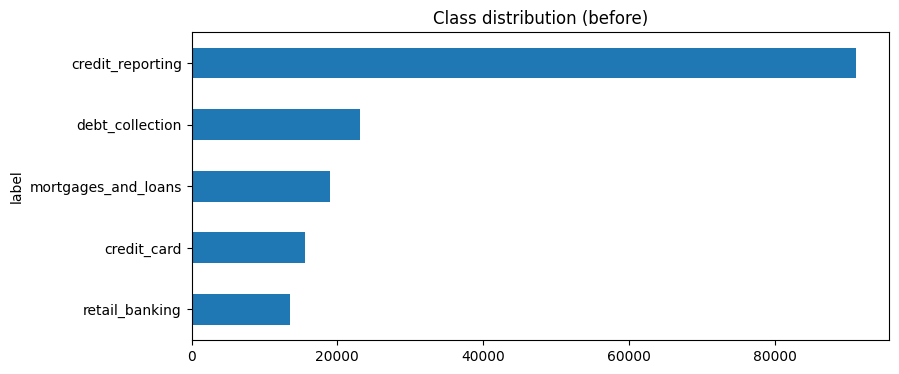

In [3]:
df["label"].value_counts().plot(kind="barh", figsize=(9, 4), title="Class distribution (before)")
plt.gca().invert_yaxis(); plt.show()

In [4]:
counts = df["label"].value_counts()
df = df[df["label"].isin(counts[counts >= MIN_PER_CLASS].index)]
if len(df) > SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=SEED)
df = df.reset_index(drop=True)

classes = sorted(df["label"].unique())
label2id = {c: i for i, c in enumerate(classes)}
id2label = {i: c for c, i in label2id.items()}
df["y"] = df["label"].map(label2id)
NUM_CLASSES = len(classes)

print("Classes:", classes)
df["label"].value_counts()

Classes: ['credit_card', 'credit_reporting', 'debt_collection', 'mortgages_and_loans', 'retail_banking']


label
credit_reporting       28010
debt_collection         7208
mortgages_and_loans     5782
credit_card             4818
retail_banking          4182
Name: count, dtype: int64

## 4) Preprocessing and Train / Validation / Test Split
Cleaning steps: lowercase, remove numbers/punctuation/special characters, remove stop words, lemmatize.

The original text stays in `raw` (DistilBERT prefers natural text); the cleaned text goes in `clean` (used by the RNN models).

In [5]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r"x{2,}|[^a-z\s]", " ", str(text).lower())
    words = [w for w in text.split() if w not in stop_words and len(w) > 2]
    return " ".join(lemmatizer.lemmatize(w) for w in words)

df["clean"] = df["raw"].apply(clean_text)
df = df[df["clean"].str.split().str.len() > 3].reset_index(drop=True)   # drop near-empty texts
df["clean"].str.split().str.len().describe()

count    49582.000000
mean        79.452563
std        104.293900
min          4.000000
25%         27.000000
50%         50.000000
75%         94.000000
max       2295.000000
Name: clean, dtype: float64

Split: 70% train, 15% validation, 15% test. `stratify` keeps class proportions the same in every split. The splits are also saved to disk so the DistilBERT step uses exactly the same data.

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

os.makedirs("/kaggle/working/splits", exist_ok=True)
train_df[["raw", "y"]].to_csv("/kaggle/working/splits/train.csv", index=False)
test_df[["raw", "y"]].to_csv("/kaggle/working/splits/test.csv", index=False)
json.dump(classes, open("/kaggle/working/splits/classes.json", "w"))

34707 7437 7438


## 5) Fine-tune DistilBERT (HuggingFace)
This runs as a **separate Python process**, so PyTorch never shares memory with TensorFlow (that conflict was killing the kernel).
The script reads the saved splits, trains for 3 epochs with a class-weighted loss, saves the predictions on the test set, and saves the model to `best_model/`.

In [7]:
%%writefile /kaggle/working/train_distilbert.py
import os, json
os.environ["CUDA_VISIBLE_DEVICES"] = "0"          # use a single GPU

import numpy as np, pandas as pd, torch
from datasets import Dataset
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

NAME, OUT = "distilbert-base-uncased", "/kaggle/working"
train = pd.read_csv(f"{OUT}/splits/train.csv")
test = pd.read_csv(f"{OUT}/splits/test.csv")
classes = json.load(open(f"{OUT}/splits/classes.json"))
id2label = dict(enumerate(classes))

weights = torch.tensor(compute_class_weight("balanced", classes=np.arange(len(classes)), y=train["y"].values),
                       dtype=torch.float)

tok = AutoTokenizer.from_pretrained(NAME)
def prep(d):
    ds = Dataset.from_dict({"text": d["raw"].tolist(), "label": d["y"].tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=128), batched=True, remove_columns=["text"])
train_ds, test_ds = prep(train), prep(test)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        out = model(**inputs)
        loss = torch.nn.functional.cross_entropy(out.logits, labels, weight=weights.to(out.logits.device))
        return (loss, out) if return_outputs else loss

model = AutoModelForSequenceClassification.from_pretrained(
    NAME, num_labels=len(classes), id2label=id2label, label2id={c: i for i, c in id2label.items()})

args = TrainingArguments(output_dir=f"{OUT}/tmp", num_train_epochs=3, learning_rate=2e-5,
                         per_device_train_batch_size=16, per_device_eval_batch_size=64,
                         fp16=torch.cuda.is_available(), save_strategy="no", report_to="none")
trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, data_collator=DataCollatorWithPadding(tok))
trainer.train()

np.save(f"{OUT}/distilbert_preds.npy", trainer.predict(test_ds).predictions.argmax(-1))
trainer.save_model(f"{OUT}/best_model"); tok.save_pretrained(f"{OUT}/best_model")
print("DONE")

Writing /kaggle/working/train_distilbert.py


In [8]:
!python -u /kaggle/working/train_distilbert.py

config.json: 100%|█████████████████████████████| 483/483 [00:00<00:00, 2.59MB/s]
tokenizer_config.json: 100%|██████████████████| 48.0/48.0 [00:00<00:00, 271kB/s]
vocab.txt: 100%|█████████████████████████████| 232k/232k [00:00<00:00, 29.0MB/s]
tokenizer.json: 100%|████████████████████████| 466k/466k [00:00<00:00, 30.5MB/s]
Map: 100%|█████████████████████████| 7438/7438 [00:01<00:00, 6209.16 examples/s]

model.safetensors: downloading bytes: ███████████▉          |  146MB, 7.52MB/s  
model.safetensors: downloading bytes: ████████████████▉     |  207MB, 14.1MB/s  
model.safetensors: downloading bytes: ██████████████████████|  250MB, 24.0MB/s  
model.safetensors: reconstructing file: 100%|██████|  268MB /  268MB, 25.8MB/s  
Loading weights: 100%|██████████████████████| 100/100 [00:00<00:00, 2815.73it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.

## 6) TensorFlow Setup
Now that DistilBERT is done, we import TensorFlow. `set_memory_growth` stops it from grabbing the whole GPU.

In [9]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
tf.random.set_seed(SEED)

## 7) Tokenization, Padding and Class Weights
- Each word gets an integer ID (most frequent first). `0` = padding, `1` = unknown word.
- Every text is padded to `MAX_LEN`. Zeros go at the **start** so the last real words sit next to the output, which works better for RNNs.
- Class weights give small classes a larger weight during training.

In [10]:
counter = Counter(w for t in train_df["clean"] for w in t.split())
vocab = {w: i + 2 for i, (w, _) in enumerate(counter.most_common(VOCAB_SIZE - 2))}

def encode(text):
    ids = [vocab.get(w, 1) for w in text.split()][:MAX_LEN]
    return [0] * (MAX_LEN - len(ids)) + ids

def encode_df(d):
    return np.array([encode(t) for t in d["clean"]], dtype="int32")

X_train, X_val, X_test = encode_df(train_df), encode_df(val_df), encode_df(test_df)
y_train, y_val, y_test = train_df["y"].values, val_df["y"].values, test_df["y"].values

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = {i: float(w) for i, w in enumerate(cw)}
print(X_train.shape, X_val.shape, X_test.shape)
pd.Series(class_weights).rename(id2label).round(2)

(34707, 200) (7437, 200) (7438, 200)


credit_card            2.06
credit_reporting       0.36
debt_collection        1.38
mortgages_and_loans    1.72
retail_banking         2.39
dtype: float64

## 8) Helper Functions
One evaluation function is used for all 4 models, so the comparison is fair. It prints precision / recall / F1 per class, draws the confusion matrix, and stores the macro scores in `results`.

In [11]:
results = {}

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    results[name] = {"Accuracy": acc, "Precision": p, "Recall": r, "F1": f1}
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=classes, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.title(f"Confusion Matrix - {name}"); plt.xlabel("Predicted"); plt.ylabel("True")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

def plot_history(h, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for a, m in zip(ax, ["loss", "accuracy"]):
        a.plot(h.history[m], label="train"); a.plot(h.history["val_" + m], label="val")
        a.set_title(f"{name} {m}"); a.legend()
    plt.show()

## 9) SimpleRNN, LSTM and GRU
All three share the same architecture: `Embedding -> RNN layer -> Dropout -> Dense -> Softmax`. Only the recurrent layer changes.
`EarlyStopping` stops training when validation loss stops improving, which is why training ends before `EPOCHS`.

In [12]:
def build_model(rnn_type):
    rnn_layer = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[rnn_type]
    model = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMB_DIM),
        rnn_layer(64),
        layers.Dropout(0.4),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model

def train_and_eval(rnn_type):
    model = build_model(rnn_type)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weights, callbacks=[es], verbose=2)
    plot_history(hist, rnn_type)
    evaluate(rnn_type, y_test, model.predict(X_test, batch_size=256).argmax(axis=1))
    return model

keras_models = {}

### 9.1 SimpleRNN

Epoch 1/15
272/272 - 14s - 50ms/step - accuracy: 0.4828 - loss: 1.3246 - val_accuracy: 0.5370 - val_loss: 1.0784
Epoch 2/15
272/272 - 5s - 19ms/step - accuracy: 0.6316 - loss: 0.9914 - val_accuracy: 0.6879 - val_loss: 0.8554
Epoch 3/15
272/272 - 5s - 19ms/step - accuracy: 0.7316 - loss: 0.7394 - val_accuracy: 0.7055 - val_loss: 0.8127
Epoch 4/15
272/272 - 5s - 19ms/step - accuracy: 0.7848 - loss: 0.5941 - val_accuracy: 0.7510 - val_loss: 0.7258
Epoch 5/15
272/272 - 5s - 19ms/step - accuracy: 0.8229 - loss: 0.4602 - val_accuracy: 0.7773 - val_loss: 0.7000
Epoch 6/15
272/272 - 5s - 19ms/step - accuracy: 0.8267 - loss: 0.4166 - val_accuracy: 0.6893 - val_loss: 0.9045
Epoch 7/15
272/272 - 5s - 19ms/step - accuracy: 0.8473 - loss: 0.3361 - val_accuracy: 0.7549 - val_loss: 0.8054
Epoch 8/15
272/272 - 5s - 19ms/step - accuracy: 0.8886 - loss: 0.2554 - val_accuracy: 0.7667 - val_loss: 0.8426


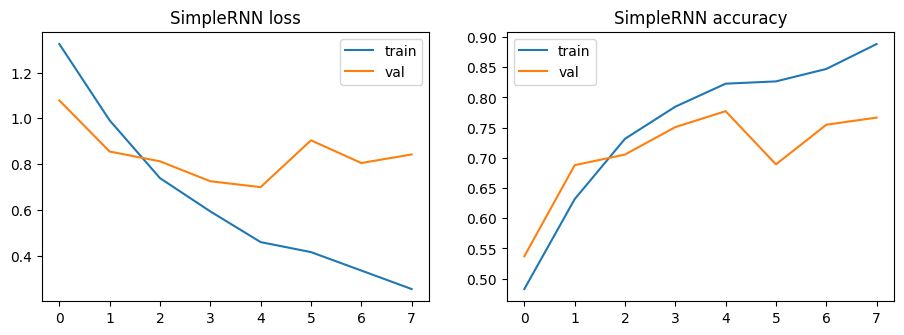

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
===== SimpleRNN =====
                     precision    recall  f1-score   support

        credit_card       0.53      0.75      0.62       722
   credit_reporting       0.90      0.85      0.87      4151
    debt_collection       0.66      0.68      0.67      1076
mortgages_and_loans       0.70      0.81      0.75       866
     retail_banking       0.79      0.50      0.61       623

           accuracy                           0.78      7438
          macro avg       0.72      0.72      0.71      7438
       weighted avg       0.80      0.78      0.78      7438



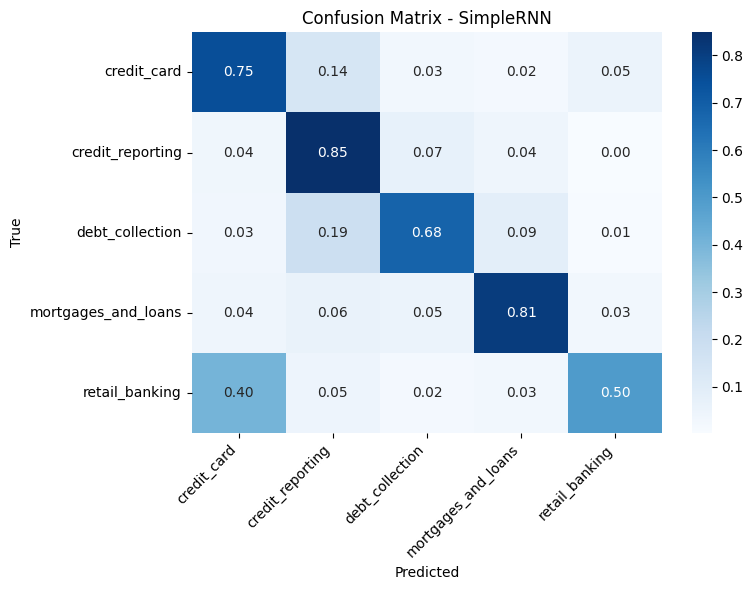

In [13]:
keras_models["SimpleRNN"] = train_and_eval("SimpleRNN")

### 9.2 LSTM

Epoch 1/15
272/272 - 9s - 32ms/step - accuracy: 0.6304 - loss: 1.0509 - val_accuracy: 0.7953 - val_loss: 0.6136
Epoch 2/15
272/272 - 4s - 14ms/step - accuracy: 0.8035 - loss: 0.6419 - val_accuracy: 0.7913 - val_loss: 0.6420
Epoch 3/15
272/272 - 4s - 14ms/step - accuracy: 0.8331 - loss: 0.5377 - val_accuracy: 0.7413 - val_loss: 0.8179
Epoch 4/15
272/272 - 4s - 14ms/step - accuracy: 0.8535 - loss: 0.4516 - val_accuracy: 0.8212 - val_loss: 0.5886
Epoch 5/15
272/272 - 4s - 14ms/step - accuracy: 0.8762 - loss: 0.3822 - val_accuracy: 0.8118 - val_loss: 0.6013
Epoch 6/15
272/272 - 4s - 14ms/step - accuracy: 0.8814 - loss: 0.3394 - val_accuracy: 0.8315 - val_loss: 0.5578
Epoch 7/15
272/272 - 4s - 14ms/step - accuracy: 0.8761 - loss: 0.4016 - val_accuracy: 0.8327 - val_loss: 0.5869
Epoch 8/15
272/272 - 4s - 14ms/step - accuracy: 0.9022 - loss: 0.2893 - val_accuracy: 0.8208 - val_loss: 0.6195
Epoch 9/15
272/272 - 4s - 14ms/step - accuracy: 0.9034 - loss: 0.2717 - val_accuracy: 0.7734 - val_loss:

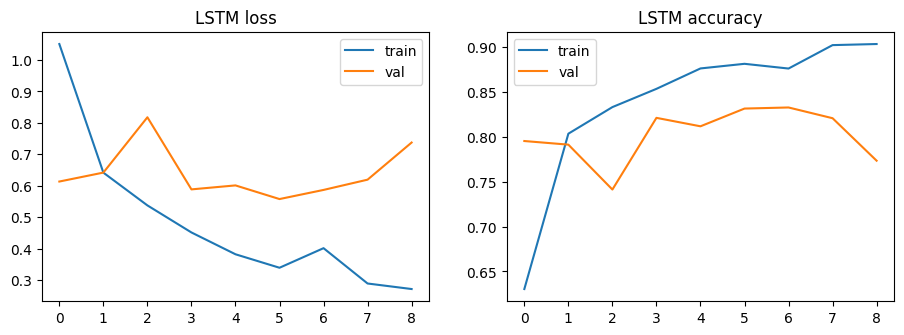

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
===== LSTM =====
                     precision    recall  f1-score   support

        credit_card       0.66      0.79      0.72       722
   credit_reporting       0.94      0.85      0.89      4151
    debt_collection       0.68      0.82      0.74      1076
mortgages_and_loans       0.78      0.79      0.78       866
     retail_banking       0.82      0.80      0.81       623

           accuracy                           0.83      7438
          macro avg       0.77      0.81      0.79      7438
       weighted avg       0.85      0.83      0.84      7438



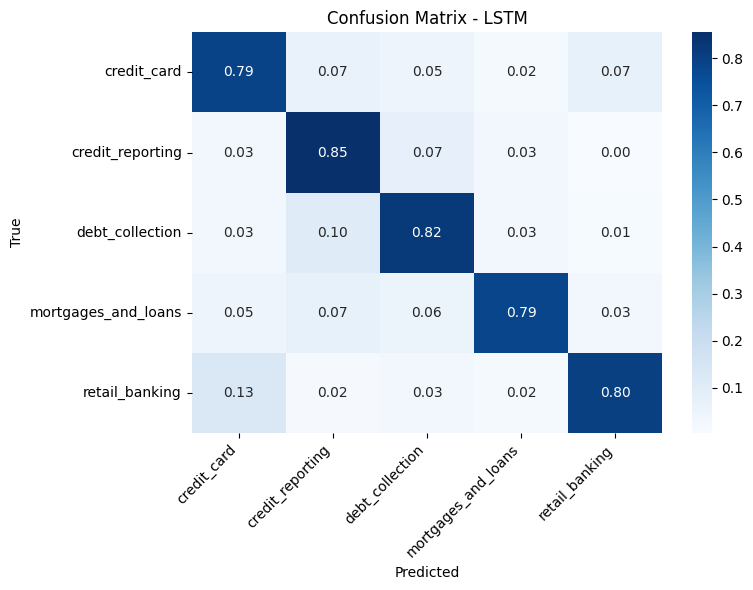

In [14]:
keras_models["LSTM"] = train_and_eval("LSTM")

### 9.3 GRU

Epoch 1/15
272/272 - 5s - 19ms/step - accuracy: 0.6342 - loss: 1.0646 - val_accuracy: 0.7749 - val_loss: 0.6493
Epoch 2/15
272/272 - 4s - 13ms/step - accuracy: 0.7898 - loss: 0.6087 - val_accuracy: 0.8054 - val_loss: 0.5789
Epoch 3/15
272/272 - 4s - 13ms/step - accuracy: 0.8360 - loss: 0.4611 - val_accuracy: 0.8208 - val_loss: 0.5462
Epoch 4/15
272/272 - 4s - 13ms/step - accuracy: 0.8614 - loss: 0.3799 - val_accuracy: 0.8370 - val_loss: 0.5072
Epoch 5/15
272/272 - 4s - 13ms/step - accuracy: 0.8760 - loss: 0.3329 - val_accuracy: 0.8291 - val_loss: 0.5487
Epoch 6/15
272/272 - 4s - 13ms/step - accuracy: 0.8912 - loss: 0.2883 - val_accuracy: 0.8338 - val_loss: 0.5658
Epoch 7/15
272/272 - 4s - 13ms/step - accuracy: 0.9031 - loss: 0.2518 - val_accuracy: 0.8319 - val_loss: 0.5941


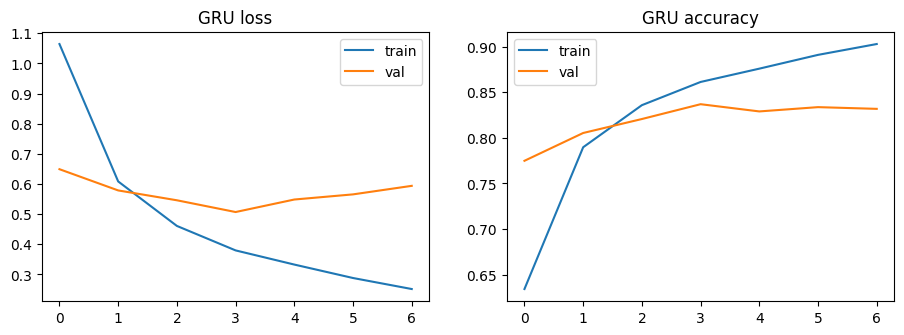

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
===== GRU =====
                     precision    recall  f1-score   support

        credit_card       0.66      0.83      0.74       722
   credit_reporting       0.93      0.88      0.90      4151
    debt_collection       0.69      0.79      0.74      1076
mortgages_and_loans       0.80      0.75      0.77       866
     retail_banking       0.86      0.80      0.83       623

           accuracy                           0.84      7438
          macro avg       0.79      0.81      0.80      7438
       weighted avg       0.85      0.84      0.84      7438



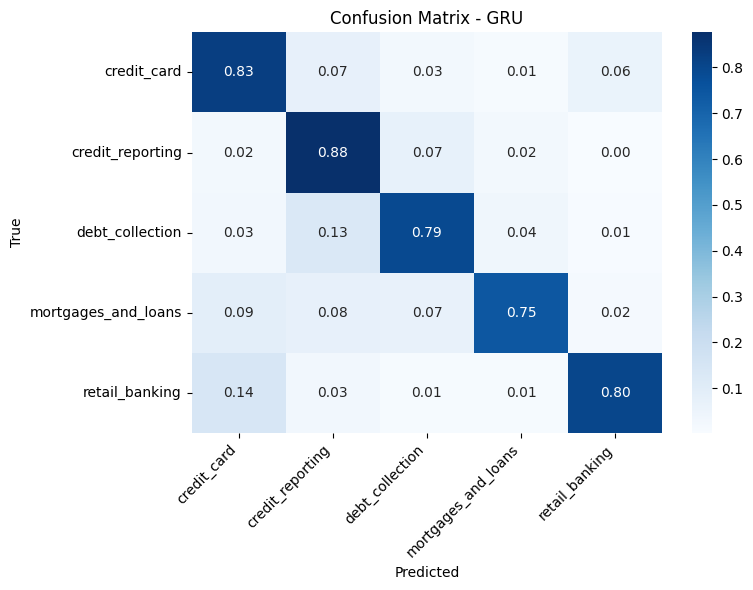

In [15]:
keras_models["GRU"] = train_and_eval("GRU")

## 10) Evaluate DistilBERT
We load the predictions that the DistilBERT script saved and evaluate them with the same function, on the same test set.

===== DistilBERT =====
                     precision    recall  f1-score   support

        credit_card       0.76      0.79      0.77       722
   credit_reporting       0.94      0.89      0.92      4151
    debt_collection       0.75      0.82      0.78      1076
mortgages_and_loans       0.79      0.84      0.82       866
     retail_banking       0.87      0.89      0.88       623

           accuracy                           0.87      7438
          macro avg       0.82      0.85      0.83      7438
       weighted avg       0.87      0.87      0.87      7438



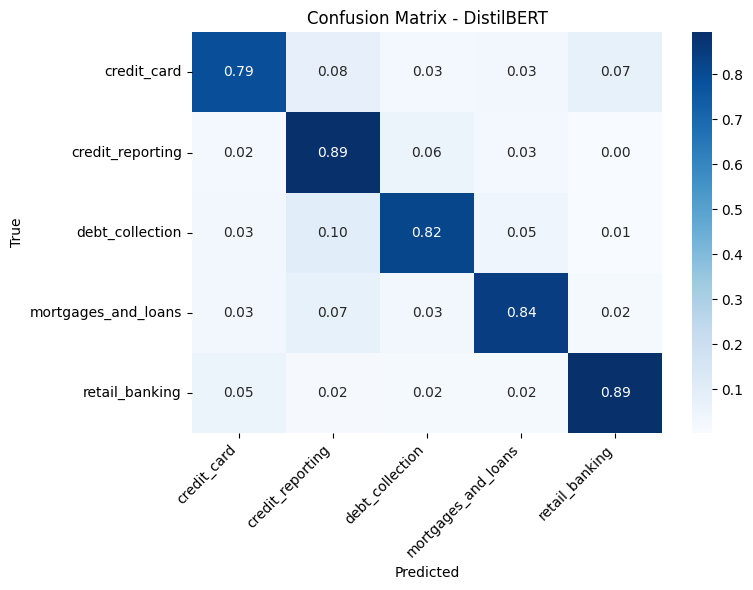

In [16]:
y_pred_bert = np.load("/kaggle/working/distilbert_preds.npy")
assert len(y_pred_bert) == len(y_test), "Prediction size does not match the test set"
evaluate("DistilBERT", y_test, y_pred_bert)

## 11) Compare the 4 Models
Macro-averaged scores on the test set. F1 is the main metric because the classes are imbalanced (accuracy alone can be misleading).

,Accuracy,Precision,Recall,F1
DistilBERT,0.8666,0.8214,0.8475,0.8338
GRU,0.8379,0.7895,0.8087,0.7960
LSTM,0.8318,0.7747,0.8120,0.7903
SimpleRNN,0.7810,0.7162,0.7175,0.7056


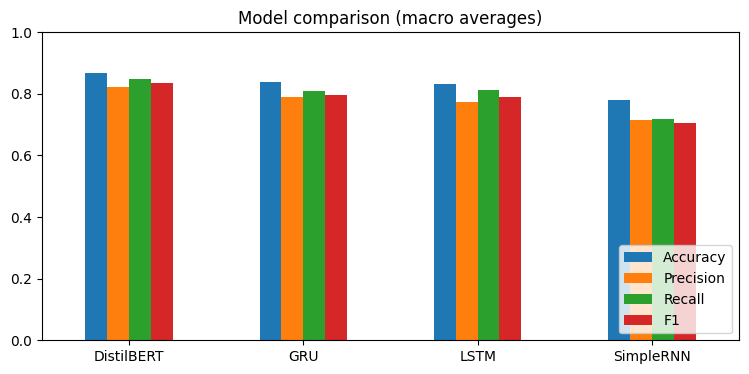

Best model: DistilBERT


In [17]:
res_df = pd.DataFrame(results).T.sort_values("F1", ascending=False).round(4)
display(res_df)

res_df.plot(kind="bar", figsize=(9, 4), title="Model comparison (macro averages)")
plt.ylim(0, 1); plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.show()
print("Best model:", res_df.index[0])

## 12) Deployment
The fine-tuned model is saved in `/kaggle/working/best_model`. Download that folder and put it next to `app.py`, then run:
```
python app.py
```